# Random Forest Baseline and Evaluation

COSC 50523 — Deep Minds

This notebook will train a Random Forest classifier using the same
prepared dataset and splits as the other project models.

Current progress:
- Load and check the prepared training and validation data.
- Define and verify a reusable evaluation function.

The prepared labels use:
- 0 = legitimate
- 1 = phishing

A Random Forest baseline has been trained and evaluated on the validation split.

In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from pathlib import Path

# Location of our shared project folder in Google Drive.
data_folder = Path('/content/drive/MyDrive/DeepMinds')

if data_folder.exists():
    print("Project folder found!\n")

    for file in sorted(data_folder.iterdir()):
        print(file.name)
else:
    print("Folder not found. Check the shortcut's name and location.")

Project folder found!

01_data_preprocesssing.ipynb
04_mlp_experiment.ipynb
PhiUSIIL_Phishing_URL_Dataset.csv
X_test.csv
X_train.csv
X_val.csv
mlp_loss_curve.png
y_test.csv
y_train.csv
y_val.csv


In [3]:
import pandas as pd

# X contains the website features the model will learn from.
X_train = pd.read_csv(data_folder / 'X_train.csv')
X_val = pd.read_csv(data_folder / 'X_val.csv')

# y contains the correct label for each website.
# Selecting the "label" column gives us one list of answers.
y_train = pd.read_csv(data_folder / 'y_train.csv')['label']
y_val = pd.read_csv(data_folder / 'y_val.csv')['label']

print("Training features:", X_train.shape)
print("Training labels:", y_train.shape)
print("Validation features:", X_val.shape)
print("Validation labels:", y_val.shape)

Training features: (165056, 50)
Training labels: (165056,)
Validation features: (35369, 50)
Validation labels: (35369,)


In [4]:
# Confirm that each website has one label.
assert len(X_train) == len(y_train), "Training counts do not match."
assert len(X_val) == len(y_val), "Validation counts do not match."

# Both splits must contain the same features in the same order.
assert X_train.columns.equals(X_val.columns), "Feature columns differ."

# The answer must not accidentally be included as an input feature.
assert 'label' not in X_train.columns, "Target label found in inputs."

for name, X, y in [
    ('Training', X_train, y_train),
    ('Validation', X_val, y_val),
]:
    assert X.select_dtypes(include='number').shape[1] == X.shape[1], \
        f"{name}: non-numeric features found."
    assert not X.isna().any().any(), f"{name}: missing feature values."
    assert not y.isna().any(), f"{name}: missing labels."
    assert set(y.unique()) == {0, 1}, f"{name}: unexpected labels."

    print(f"\n{name} label distribution:")
    summary = pd.DataFrame({
        'Count': y.value_counts().sort_index(),
        'Percent': y.value_counts(normalize=True).sort_index() * 100,
    })
    summary.index = ['Legitimate (0)', 'Phishing (1)']
    print(summary.round(2))

print("\nAll basic data checks passed.")


Training label distribution:
                Count  Percent
Legitimate (0)  94395    57.19
Phishing (1)    70661    42.81

Validation label distribution:
                Count  Percent
Legitimate (0)  20227    57.19
Phishing (1)    15142    42.81

All basic data checks passed.


## Evaluate predictions

Phishing is the positive class (1).
A false positive is a legitimate website flagged as phishing.
A false negative is a phishing website incorrectly classified as legitimate.

In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

def evaluate_model(name, split, y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    results = {
        'Model': name,
        'Split': split,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        'Recall': recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        'F1': f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        'False positives': int(fp),
        'False negatives': int(fn),
    }

    display(pd.DataFrame([results]).round(4))

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['Legitimate', 'Phishing'],
    ).plot(cmap='Blues', values_format='d')

    plt.title(f'{name} — {split}')
    plt.show()

    return results

,Model,Split,Accuracy,Precision,Recall,F1,False positives,False negatives
0,Function check — invented example,Example only,0.6667,0.6667,0.6667,0.6667,1,1


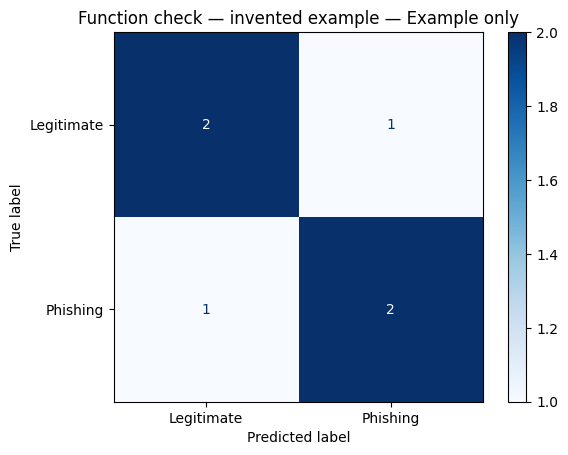

Evaluation check passed.


In [6]:
# Made-up labels to verify the function, not project results.
example_actual = [0, 0, 0, 1, 1, 1]
example_predictions = [0, 0, 1, 0, 1, 1]

example_results = evaluate_model(
    'Function check — invented example',
    'Example only',
    example_actual,
    example_predictions,
)

assert example_results['False positives'] == 1
assert example_results['False negatives'] == 1

print("Evaluation check passed.")

## Random Forest baseline

This run uses 100 decision trees and random seed 42.
The model learns from the training split and is evaluated on validation data.
It uses the same 50 prepared features as the MLP.

Training Random Forest...
Evaluating on validation data...


,Model,Split,Accuracy,Precision,Recall,F1,False positives,False negatives
0,Random Forest,Validation,1.0,1.0,1.0,1.0,0,0


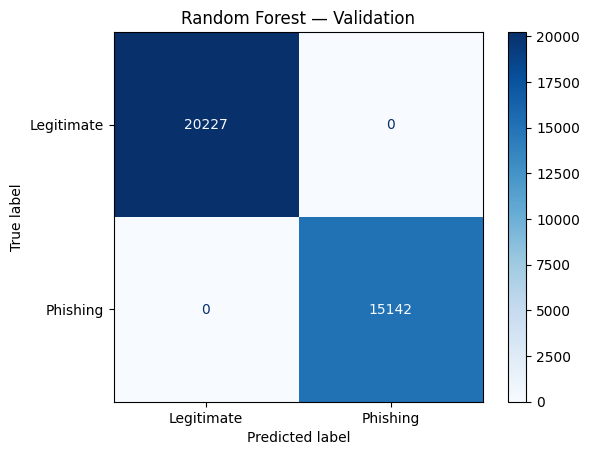

In [7]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
)

print("Training Random Forest...")
rf.fit(X_train, y_train)

print("Evaluating on validation data...")
val_predictions = rf.predict(X_val)

rf_results = evaluate_model(
    'Random Forest',
    'Validation',
    y_val,
    val_predictions,
)

## Preliminary validation results

The Random Forest correctly classified all 35,369 validation examples:
20,227 legitimate websites and 15,142 phishing websites. Accuracy,
precision, recall, and F1 were all 1.0, with zero false positives and
zero false negatives.

This is a preliminary result on the current validation split.
Further checks are needed for overlap between splits and potential
leakage in the supplied features. This result does not establish
perfect performance on new real-world websites.

The test set was not used in this notebook.